<a href="https://colab.research.google.com/github/michael-palomino-tm/Ingenier-a-de-Soluciones-con-Inteligencia-Artificial/blob/Mistral/RA3/IL3.2/3_2_2_Laboratorio_4_Auditoria_Trazabilidad_MercadoAndes_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ISY0101 · Ingeniería de Soluciones con IA
## EA3 · Actividad 3.2 · Laboratorio 4
### Demostración de auditoría y diagnóstico de trazabilidad — MercadoAndes

**Objetivo:** observar cómo se reconstruyen sesiones, solicitudes y operaciones para diagnosticar fallas e ineficiencias a partir de registros estructurados.

**Demostración completa:** todas las celdas están implementadas y pueden ejecutarse de arriba hacia abajo. No se requiere completar ni modificar código.

Los datos son **sintéticos** y reproducibles; no son ejecuciones reales de Mistral ni trazas exportadas desde LangSmith. La trazabilidad describe operaciones observables instrumentadas, no el razonamiento interno privado del modelo.

## 1. Caso: MercadoAndes
MercadoAndes dispone de un asistente que consulta ventas, operaciones y reclamos. Los reportes señalan demoras, reintentos y resultados incompletos. Analizaremos el **registro de operaciones**, no solamente las respuestas del asistente.

| Campo | Significado |
|---|---|
| `session_id` | Conversación que puede contener varias solicitudes. |
| `trace_id` | Solicitud individual. |
| `span_id` | Operación individual registrada. |
| `parent_span_id` | Operación padre; `null` para el span raíz. |
| `tipo_span` | AGENT, TOOL, LLM o RETRIEVER. |
| `estado` | Resultado registrado de cada operación. |
| `inicio`, `fin`, `duracion_ms` | Momento y duración de ejecución. |

**Precisión:** el tiempo de una operación padre incluye los tiempos de sus hijos. No sumamos indiscriminadamente duración del padre y de los hijos.

## 2. Preparación
Utilizamos `pandas`, `matplotlib` y bibliotecas estándar incluidas en Google Colab. **No hace falta instalar paquetes ni configurar API keys.**

In [1]:
# Bibliotecas de análisis y visualización.
import json
from pathlib import Path
from datetime import datetime, timedelta, timezone
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# Ampliamos la visualización de columnas y texto en las tablas.
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
print("Entorno listo. Pandas:", pd.__version__)

Entorno listo. Pandas: 2.2.3


## 3. Dataset sintético de trazabilidad
Generamos localmente un archivo JSONL: **un objeto JSON por línea**. Las fechas, identificadores y duraciones son fijos para que el diagnóstico pueda reproducirse en cualquier ejecución.

In [2]:
# Fecha de referencia ficticia; no corresponde a una ejecución en tiempo real.
BASE = datetime(2026, 11, 18, 10, 0, tzinfo=timezone.utc)
EVENTOS = []

def agregar(trace, session, span, parent, nombre, tipo, inicio_ms, duracion_ms,
            estado="ok", codigo_error=None, detalle=""):
    """Agrega un evento estructurado a la lista de registros sintéticos.

    - inicio_ms: desplazamiento desde BASE en milisegundos.
    - parent=None: este evento es la raíz de una traza.
    - El tiempo registrado permite comprobar relaciones temporales entre padre e hijo.
    """
    inicio = BASE + timedelta(milliseconds=inicio_ms)
    fin = inicio + timedelta(milliseconds=duracion_ms)
    EVENTOS.append({
        "session_id": session, "trace_id": trace, "span_id": span,
        "parent_span_id": parent, "nombre": nombre, "tipo_span": tipo,
        "inicio": inicio.isoformat(), "fin": fin.isoformat(),
        "duracion_ms": duracion_ms, "estado": estado,
        "codigo_error": codigo_error, "detalle": detalle,
    })

# T-101: ejecución de referencia (sin anomalías conocidas para el auditor).
agregar("T-101","SES-01","S-101-0",None,"resolver_solicitud","AGENT",0,1550)
agregar("T-101","SES-01","S-101-1","S-101-0","consultar_ventas","TOOL",100,220)
agregar("T-101","SES-01","S-101-2","S-101-0","respuesta_mistral","LLM",400,980)

# T-102: una operación de consulta se repite varias veces dentro de la misma solicitud.
agregar("T-102","SES-01","S-102-0",None,"resolver_solicitud","AGENT",10000,4800)
agregar("T-102","SES-01","S-102-1","S-102-0","consultar_reclamos","TOOL",10100,300)
agregar("T-102","SES-01","S-102-2","S-102-0","consultar_reclamos","TOOL",10450,310)
agregar("T-102","SES-01","S-102-3","S-102-0","consultar_reclamos","TOOL",10800,295)
agregar("T-102","SES-01","S-102-4","S-102-0","respuesta_mistral","LLM",11200,3400)

# T-201: la API del LLM rechaza una llamada; el flujo espera y luego logra completarse.
agregar("T-201","SES-02","S-201-0",None,"resolver_solicitud","AGENT",30000,7150)
agregar("T-201","SES-02","S-201-1","S-201-0","consultar_operaciones","TOOL",30100,250)
agregar("T-201","SES-02","S-201-2","S-201-0","respuesta_mistral_intento_1","LLM",30400,150,"error","429","API limitó temporalmente la solicitud")
agregar("T-201","SES-02","S-201-3","S-201-0","esperar_reintento","TOOL",30550,4000,"ok",None,"Espera programada después del error 429")
agregar("T-201","SES-02","S-201-4","S-201-0","respuesta_mistral_intento_2","LLM",34600,2350)

# T-301: una búsqueda tarda mucho más que las demás operaciones.
agregar("T-301","SES-03","S-301-0",None,"resolver_solicitud","AGENT",50000,9200)
agregar("T-301","SES-03","S-301-1","S-301-0","buscar_documentos","RETRIEVER",50100,6900)
agregar("T-301","SES-03","S-301-2","S-301-0","respuesta_mistral","LLM",57200,1800)

# T-302: la solicitud raíz se registra OK, aunque una herramienta hija falló.
agregar("T-302","SES-03","S-302-0",None,"resolver_solicitud","AGENT",65000,1050,"ok",None,"Error capturado por el ejecutor")
agregar("T-302","SES-03","S-302-1","S-302-0","consultar_ventas","TOOL",65050,120)
agregar("T-302","SES-03","S-302-2","S-302-0","consultar_operaciones","TOOL",65220,80,"error","TIMEOUT","Se agotó el tiempo de espera de la herramienta")
agregar("T-302","SES-03","S-302-3","S-302-0","respuesta_degradada","LLM",65350,600)

# T-401: otra ejecución ordinaria, perteneciente a una nueva sesión.
agregar("T-401","SES-04","S-401-0",None,"resolver_solicitud","AGENT",80000,1850)
agregar("T-401","SES-04","S-401-1","S-401-0","consultar_ventas","TOOL",80100,240)
agregar("T-401","SES-04","S-401-2","S-401-0","respuesta_mistral","LLM",80400,1250)

# Guardamos el dataset en formato JSON Lines, habitual para logs estructurados.
ARCHIVO = Path("mercadoandes_semana15_logs.jsonl")
with ARCHIVO.open("w", encoding="utf-8") as archivo:
    for evento in EVENTOS:
        archivo.write(json.dumps(evento, ensure_ascii=False) + "\n")

print(f"Archivo preparado: {ARCHIVO} ({len(EVENTOS)} registros)")

Archivo preparado: mercadoandes_semana15_logs.jsonl (23 registros)


## 4. Carga y validación
Leemos el archivo y verificamos reglas estructurales básicas. Las validaciones no sustituyen una auditoría completa: permiten detectar registros imposibles o mal formados antes de analizarlos.

In [3]:
# Cada línea del JSONL es un objeto independiente.
with ARCHIVO.open(encoding="utf-8") as archivo:
    registros = [json.loads(linea) for linea in archivo if linea.strip()]

df = pd.DataFrame(registros)

# Convertimos texto ISO 8601 a datetimes con zona horaria UTC.
for columna in ("inicio", "fin"):
    df[columna] = pd.to_datetime(df[columna], utc=True, format="ISO8601")

# Comprobaciones sencillas para detectar inconsistencias de carga.
assert df["span_id"].is_unique, "Hay identificadores de span repetidos."
assert (df["duracion_ms"] >= 0).all(), "Hay duraciones negativas."
assert (df["fin"] >= df["inicio"]).all(), "Hay spans con fin anterior al inicio."

print("Registros:", len(df))
print("Sesiones:", df["session_id"].nunique())
print("Trazas:", df["trace_id"].nunique())
display(df.head(8))

Registros: 23
Sesiones: 4
Trazas: 6


,session_id,trace_id,span_id,parent_span_id,nombre,tipo_span,inicio,fin,duracion_ms,estado,codigo_error,detalle
0,SES-01,T-101,S-101-0,None,resolver_solicitud,AGENT,2026-11-18 10:00:00+00:00,2026-11-18 10:00:01.550000+00:00,1550,ok,None,
1,SES-01,T-101,S-101-1,S-101-0,consultar_ventas,TOOL,2026-11-18 10:00:00.100000+00:00,2026-11-18 10:00:00.320000+00:00,220,ok,None,
2,SES-01,T-101,S-101-2,S-101-0,respuesta_mistral,LLM,2026-11-18 10:00:00.400000+00:00,2026-11-18 10:00:01.380000+00:00,980,ok,None,
3,SES-01,T-102,S-102-0,None,resolver_solicitud,AGENT,2026-11-18 10:00:10+00:00,2026-11-18 10:00:14.800000+00:00,4800,ok,None,
4,SES-01,T-102,S-102-1,S-102-0,consultar_reclamos,TOOL,2026-11-18 10:00:10.100000+00:00,2026-11-18 10:00:10.400000+00:00,300,ok,None,
5,SES-01,T-102,S-102-2,S-102-0,consultar_reclamos,TOOL,2026-11-18 10:00:10.450000+00:00,2026-11-18 10:00:10.760000+00:00,310,ok,None,
6,SES-01,T-102,S-102-3,S-102-0,consultar_reclamos,TOOL,2026-11-18 10:00:10.800000+00:00,2026-11-18 10:00:11.095000+00:00,295,ok,None,
7,SES-01,T-102,S-102-4,S-102-0,respuesta_mistral,LLM,2026-11-18 10:00:11.200000+00:00,2026-11-18 10:00:14.600000+00:00,3400,ok,None,


## 5. Reconstrucción de sesiones y solicitudes
Primero agrupamos las trazas por conversación. Una conversación (`session_id`) puede incluir varios turnos, y cada turno puede disponer de su propio `trace_id`. La tabla y el diagrama resultantes permiten distinguir ambos niveles.

In [4]:
# Cada traza contiene varios spans, por lo que usamos nunique()
# y no contamos directamente las filas del archivo.
trazas_por_sesion = (
    df.groupby("session_id")["trace_id"]
      .nunique()
      .rename("solicitudes")
      .reset_index()
      .sort_values("session_id")
)
print("Solicitudes distintas por conversación:")
display(trazas_por_sesion)

# Identificamos el inicio de cada traza con la fecha de su span raíz.
raices = df[df["parent_span_id"].isna()].copy()
solicitudes = raices[["session_id", "trace_id", "inicio", "duracion_ms", "estado"]].sort_values("inicio")
print("Solicitudes ordenadas cronológicamente:")
display(solicitudes)

# Comprobación del número de conversaciones y solicitudes reales.
print(f"Sesiones: {df['session_id'].nunique()} | Trazas: {df['trace_id'].nunique()}")

Solicitudes distintas por conversación:


,session_id,solicitudes
0,SES-01,2
1,SES-02,1
2,SES-03,2
3,SES-04,1


Solicitudes ordenadas cronológicamente:


,session_id,trace_id,inicio,duracion_ms,estado
0,SES-01,T-101,2026-11-18 10:00:00+00:00,1550,ok
3,SES-01,T-102,2026-11-18 10:00:10+00:00,4800,ok
8,SES-02,T-201,2026-11-18 10:00:30+00:00,7150,ok
13,SES-03,T-301,2026-11-18 10:00:50+00:00,9200,ok
16,SES-03,T-302,2026-11-18 10:01:05+00:00,1050,ok
20,SES-04,T-401,2026-11-18 10:01:20+00:00,1850,ok


Sesiones: 4 | Trazas: 6


## 6. Reconstrucción jerárquica de spans
El `parent_span_id` permite identificar qué operación llamó a otra. Ejecutaremos automáticamente la reconstrucción de **todas las trazas**; el árbol presenta indentación para diferenciar raíces e hijos.

In [5]:
def mostrar_arbol(traza):
    """Reconstruye y muestra el árbol de spans de una sola solicitud."""
    # Asociamos a cada identificador padre todos sus hijos directos.
    hijos = {}
    for fila in traza.to_dict("records"):
        hijos.setdefault(fila["parent_span_id"], []).append(fila)
    for grupo in hijos.values():
        grupo.sort(key=lambda fila: fila["inicio"])

    # Evitamos recorridos infinitos si una relación padre-hijo fuera inválida.
    visitados = set()
    def recorrer(fila, nivel=0):
        sid = fila["span_id"]
        if sid in visitados:
            print("  " * nivel + "[advertencia: ciclo o identificador duplicado]")
            return
        visitados.add(sid)
        print("  " * nivel + f"- {sid} | {fila['nombre']} | {fila['estado']} | {fila['duracion_ms']} ms")
        for hijo in hijos.get(sid, []):
            recorrer(hijo, nivel + 1)

    # El span raíz es aquel que no tiene parent_span_id.
    for raiz in hijos.get(None, []):
        recorrer(raiz)
    if len(visitados) != len(traza):
        print(f"[advertencia: {len(traza) - len(visitados)} spans no conectados a una raíz]")

# La salida presenta las seis ejecuciones, una por trace_id.
for trace_id, traza in df.groupby("trace_id", sort=True):
    print(f"\nTRAZA {trace_id} | SESIÓN {traza['session_id'].iloc[0]}")
    mostrar_arbol(traza)


TRAZA T-101 | SESIÓN SES-01
- S-101-0 | resolver_solicitud | ok | 1550 ms
  - S-101-1 | consultar_ventas | ok | 220 ms
  - S-101-2 | respuesta_mistral | ok | 980 ms

TRAZA T-102 | SESIÓN SES-01
- S-102-0 | resolver_solicitud | ok | 4800 ms
  - S-102-1 | consultar_reclamos | ok | 300 ms
  - S-102-2 | consultar_reclamos | ok | 310 ms
  - S-102-3 | consultar_reclamos | ok | 295 ms
  - S-102-4 | respuesta_mistral | ok | 3400 ms

TRAZA T-201 | SESIÓN SES-02
- S-201-0 | resolver_solicitud | ok | 7150 ms
  - S-201-1 | consultar_operaciones | ok | 250 ms
  - S-201-2 | respuesta_mistral_intento_1 | error | 150 ms
  - S-201-3 | esperar_reintento | ok | 4000 ms
  - S-201-4 | respuesta_mistral_intento_2 | ok | 2350 ms

TRAZA T-301 | SESIÓN SES-03
- S-301-0 | resolver_solicitud | ok | 9200 ms
  - S-301-1 | buscar_documentos | ok | 6900 ms
  - S-301-2 | respuesta_mistral | ok | 1800 ms

TRAZA T-302 | SESIÓN SES-03
- S-302-0 | resolver_solicitud | ok | 1050 ms
  - S-302-1 | consultar_ventas | ok | 1

## 7. Diagnóstico automático: operaciones repetidas
Contaremos cuántas veces aparece cada herramienta dentro de una solicitud. **Repetición no significa automáticamente error**: es una señal para investigar si hubo una necesidad legítima de consultar nuevamente o una llamada redundante.

In [6]:
# Seleccionamos las llamadas a herramientas y contamos repeticiones por traza.
frecuencia = (
    df[df["tipo_span"] == "TOOL"]
      .groupby(["trace_id", "nombre"])
      .size()
      .reset_index(name="cantidad")
      .sort_values(["cantidad", "trace_id"], ascending=[False, True])
)
print("Frecuencia de cada herramienta:")
display(frecuencia)

# Destacamos solamente los casos con más de una llamada idéntica.
repeticiones = frecuencia[frecuencia["cantidad"] > 1].copy()
print("Posibles operaciones redundantes:")
display(repeticiones if not repeticiones.empty else "No se detectaron repeticiones")

Frecuencia de cada herramienta:


,trace_id,nombre,cantidad
1,T-102,consultar_reclamos,3
0,T-101,consultar_ventas,1
2,T-201,consultar_operaciones,1
3,T-201,esperar_reintento,1
4,T-302,consultar_operaciones,1
5,T-302,consultar_ventas,1
6,T-401,consultar_ventas,1


Posibles operaciones redundantes:


,trace_id,nombre,cantidad
1,T-102,consultar_reclamos,3


## 8. Diagnóstico automático: errores y recuperaciones
Un error puede estar localizado en un span hijo, mientras el span raíz termina con `ok` porque el sistema lo gestionó o devolvió una respuesta degradada. Compararemos explícitamente ambos estados y reconstruiremos la secuencia de errores y reintentos.

In [7]:
# Recopilamos todas las operaciones que quedaron marcadas como error.
errores = df[df["estado"] == "error"].sort_values("inicio")
print("Spans con error:")
display(errores[["trace_id", "span_id", "nombre", "codigo_error", "detalle"]])

# Para cada traza investigamos la relación entre el estado de la raíz
# y la existencia de errores internos.
resumen_errores = []
for trace_id, traza in df.groupby("trace_id"):
    raiz = traza[traza["parent_span_id"].isna()].iloc[0]
    hijos_error = traza[(traza["parent_span_id"].notna()) & (traza["estado"] == "error")]
    resumen_errores.append({
        "trace_id": trace_id,
        "estado_raiz": raiz["estado"],
        "errores_hijos": len(hijos_error),
        "error_oculto_en_raiz_ok": raiz["estado"] == "ok" and len(hijos_error) > 0
    })
diagnostico_errores = pd.DataFrame(resumen_errores)
display(diagnostico_errores)

# Mostramos la secuencia completa de las trazas donde hubo errores,
# lo que permite ver un error 429 seguido de espera y un nuevo intento.
for trace_id in diagnostico_errores.loc[diagnostico_errores["errores_hijos"] > 0, "trace_id"]:
    print(f"\nSecuencia de eventos de {trace_id}:")
    display(df[df["trace_id"] == trace_id].sort_values("inicio")[[
        "span_id", "nombre", "estado", "codigo_error", "duracion_ms"
    ]])

Spans con error:


,trace_id,span_id,nombre,codigo_error,detalle
10,T-201,S-201-2,respuesta_mistral_intento_1,429,API limitó temporalmente la solicitud
18,T-302,S-302-2,consultar_operaciones,TIMEOUT,Se agotó el tiempo de espera de la herramienta


,trace_id,estado_raiz,errores_hijos,error_oculto_en_raiz_ok
0,T-101,ok,0,False
1,T-102,ok,0,False
2,T-201,ok,1,True
3,T-301,ok,0,False
4,T-302,ok,1,True
5,T-401,ok,0,False



Secuencia de eventos de T-201:


,span_id,nombre,estado,codigo_error,duracion_ms
8,S-201-0,resolver_solicitud,ok,None,7150
9,S-201-1,consultar_operaciones,ok,None,250
10,S-201-2,respuesta_mistral_intento_1,error,429,150
11,S-201-3,esperar_reintento,ok,None,4000
12,S-201-4,respuesta_mistral_intento_2,ok,None,2350



Secuencia de eventos de T-302:


,span_id,nombre,estado,codigo_error,duracion_ms
16,S-302-0,resolver_solicitud,ok,None,1050
17,S-302-1,consultar_ventas,ok,None,120
18,S-302-2,consultar_operaciones,error,TIMEOUT,80
19,S-302-3,respuesta_degradada,ok,None,600


## 9. Cuellos de botella y tiempos de espera
Ordenaremos los spans hijos según su duración. Una operación de recuperación documental lenta, un LLM o una espera programada pueden contribuir a una solicitud lenta. El gráfico permite localizar el tiempo, pero **no prueba por sí solo la causa técnica subyacente**.

,trace_id,nombre,tipo_span,duracion_ms,estado
14,T-301,buscar_documentos,RETRIEVER,6900,ok
11,T-201,esperar_reintento,TOOL,4000,ok
7,T-102,respuesta_mistral,LLM,3400,ok
12,T-201,respuesta_mistral_intento_2,LLM,2350,ok
15,T-301,respuesta_mistral,LLM,1800,ok
22,T-401,respuesta_mistral,LLM,1250,ok
2,T-101,respuesta_mistral,LLM,980,ok
19,T-302,respuesta_degradada,LLM,600,ok
5,T-102,consultar_reclamos,TOOL,310,ok
4,T-102,consultar_reclamos,TOOL,300,ok


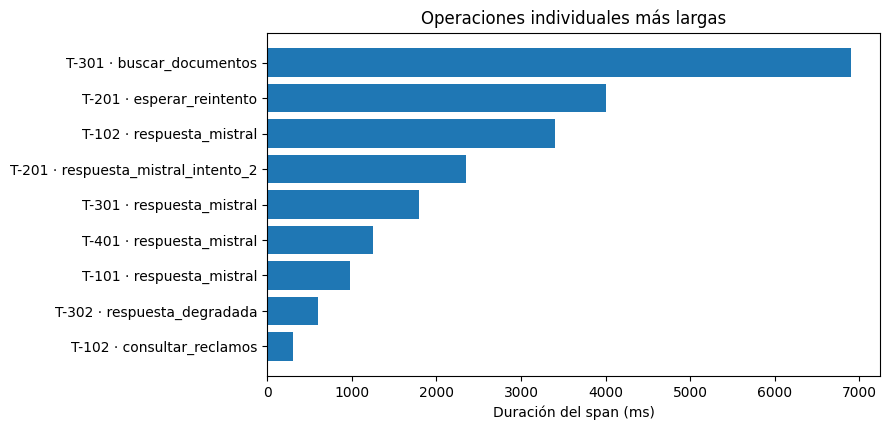

In [8]:
# Duraciones registradas en operaciones que NO son la raíz.
operaciones = df[df["parent_span_id"].notna()].copy()
ordenadas = operaciones.sort_values("duracion_ms", ascending=False)

display(ordenadas[["trace_id", "nombre", "tipo_span", "duracion_ms", "estado"]].head(12))

# Gráfico de duración de los spans hijos más largos.
seleccion = ordenadas.head(10).iloc[::-1]
plt.figure(figsize=(9, 4.4))
plt.barh(seleccion["trace_id"] + " · " + seleccion["nombre"], seleccion["duracion_ms"])
plt.xlabel("Duración del span (ms)")
plt.title("Operaciones individuales más largas")
plt.tight_layout()
plt.show()

## 10. Diagnóstico consolidado: evidencia y acciones propuestas
La tabla siguiente se genera automáticamente a partir de los datos. Cada hallazgo relaciona una **traza concreta**, una **evidencia observable** y una **acción de mejora propuesta**. Las recomendaciones son hipótesis de ingeniería que deben comprobarse posteriormente.

In [9]:
# Construimos el informe a partir de patrones detectados,
# sin escribir manualmente las filas como si fueran mediciones.
hallazgos = []

# 1. Posible repetición innecesaria de herramientas.
for _, fila in repeticiones.iterrows():
    hallazgos.append({
        "trace_id": fila["trace_id"],
        "hallazgo": "Herramienta consultada repetidamente",
        "evidencia": f"{fila['nombre']}: {fila['cantidad']} llamadas en la misma traza",
        "recomendacion": "Revisar condiciones del flujo y reutilizar resultados si son válidos"
    })

# 2. Errores 429, incluso si un reintento posterior se completa.
for trace_id in errores.loc[errores["codigo_error"] == "429", "trace_id"].unique():
    hallazgos.append({
        "trace_id": trace_id,
        "hallazgo": "Limitación temporal de API",
        "evidencia": "Span LLM con código 429 y reintento registrado",
        "recomendacion": "Aplicar límites de solicitudes, reintentos controlados y monitoreo"
    })

# 3. Operaciones de recuperación documental lentas.
retrievers = df[(df["tipo_span"] == "RETRIEVER") & (df["duracion_ms"] >= 3000)]
for _, fila in retrievers.iterrows():
    hallazgos.append({
        "trace_id": fila["trace_id"],
        "hallazgo": "Operación de recuperación lenta",
        "evidencia": f"{fila['nombre']}: {fila['duracion_ms']} ms",
        "recomendacion": "Revisar índice, consulta y tiempos de respuesta del recuperador"
    })

# 4. Raíz exitosa pese a errores en hijos: resultado posiblemente degradado.
for trace_id in diagnostico_errores.loc[diagnostico_errores["error_oculto_en_raiz_ok"], "trace_id"]:
    # Registramos este hallazgo solo si un hijo tiene error.
    fallos = errores[errores["trace_id"] == trace_id]
    if (fallos["codigo_error"] == "TIMEOUT").any():
        hallazgos.append({
            "trace_id": trace_id,
            "hallazgo": "Respuesta raíz OK con herramienta fallida",
            "evidencia": "La raíz terminó OK; consultar_operaciones registró TIMEOUT",
            "recomendacion": "Distinguir éxito parcial de éxito completo y alertar errores internos"
        })

informe = pd.DataFrame(hallazgos, columns=[
    "trace_id", "hallazgo", "evidencia", "recomendacion"
])
print(f"Hallazgos fundamentados detectados: {len(informe)}")
display(informe)

Hallazgos fundamentados detectados: 4


,trace_id,hallazgo,evidencia,recomendacion
0,T-102,Herramienta consultada repetidamente,consultar_reclamos: 3 llamadas en la misma traza,Revisar condiciones del flujo y reutilizar resultados si son válidos
1,T-201,Limitación temporal de API,Span LLM con código 429 y reintento registrado,"Aplicar límites de solicitudes, reintentos controlados y monitoreo"
2,T-301,Operación de recuperación lenta,buscar_documentos: 6900 ms,"Revisar índice, consulta y tiempos de respuesta del recuperador"
3,T-302,Respuesta raíz OK con herramienta fallida,La raíz terminó OK; consultar_operaciones registró TIMEOUT,Distinguir éxito parcial de éxito completo y alertar errores internos


## 11. Cierre de la demostración
En un sistema instrumentado, un diagnóstico profesional sigue la secuencia:

**Identificador → Operación → Evidencia observada → Hipótesis de problema → Acción propuesta.**

La correlación de sesiones, trazas y spans permite responder **dónde ocurrió** un comportamiento anómalo; la evaluación de su causa real puede requerir más información. Un `estado=ok` en la raíz no implica que todos los componentes hayan ejecutado correctamente.

Los registros son ficticios y muestran situaciones seleccionadas con fines didácticos. No permiten estimar tasas de error ni rendimiento de un proveedor real.

In [10]:
# El archivo JSONL ya quedó guardado en el entorno de Colab.
# Mostramos su ruta y tamaño, sin iniciar una descarga automática.
print(f"Archivo de evidencia: {ARCHIVO.resolve()}")
print(f"Tamaño: {ARCHIVO.stat().st_size:,} bytes")

Archivo de evidencia: /content/mercadoandes_semana15_logs.jsonl
Tamaño: 7,286 bytes
